**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Jacinto Manuel Molina Peralta
*   MATRÍCULA: A01841486

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [2]:
cardio_df = pd.read_csv('heart_disease.csv')
cardio_df = cardio_df.set_index('id')
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


In [3]:
cardio_df.nunique()

,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


Con `info()` obtuve que el dataframe tiene 918 registros y 15 columnas (el `id` quedó como índice).

* **Numéricas: 7.** `age` y `num` son enteros (`int64`), y `trestbps`, `chol`, `thalch`, `oldpeak` y `ca` son decimales (`float64`).
* **De texto: 8.** `sex`, `origin`, `cp`, `fbs`, `restecg`, `exang`, `slope` y `thal` (tipo `object`).

`fbs` y `exang` en realidad son de verdadero/falso, pero pandas las lee como texto porque tienen valores vacíos. Lo mismo pasa con `ca`: solo tiene enteros, pero aparece como decimal por los faltantes.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [4]:
# Valores únicos de las variables numéricas
print(cardio_df.select_dtypes(include='number').nunique().sort_values())
print('\nca: ', sorted(cardio_df['ca'].dropna().unique()))
print('num:', sorted(cardio_df['num'].unique()))

ca            4
num           5
age          50
oldpeak      53
trestbps     60
thalch      119
chol        216
dtype: int64

ca:  [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
num: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


Al revisar los valores únicos, `ca` solo tiene 4 valores (0, 1, 2 y 3) y `num` solo tiene 5 (del 0 al 4). Son muy pocos para ser variables numéricas continuas, así que en realidad son categorías escritas con números. Las demás numéricas (`age`, `oldpeak`, `trestbps`, `thalch` y `chol`) tienen 50 valores distintos o más, así que esas las dejé como numéricas.

In [5]:
cardio_df['ca'] = pd.Categorical(cardio_df['ca'], categories=[0, 1, 2, 3], ordered=True)
cardio_df['num'] = pd.Categorical(cardio_df['num'], categories=[0, 1, 2, 3, 4], ordered=True)

print(cardio_df['ca'].cat.categories)
print(cardio_df['num'].cat.categories)
cardio_df.dtypes

Index([0, 1, 2, 3], dtype='int64')
Index([0, 1, 2, 3, 4], dtype='int64')


,0
age,int64
sex,object
origin,object
cp,object
trestbps,float64
chol,float64
fbs,object
restecg,object
thalch,float64
exang,object


Convertí `ca` y `num` a categóricas, y las dos son **ordinales**, porque sus valores tienen un orden que sí importa:

* **`ca`** es el número de vasos sanguíneos que se ven en la fluoroscopía. Tener 3 vasos afectados es peor que tener 0, así que el orden es 0 < 1 < 2 < 3.
* **`num`** indica qué tan grave es la enfermedad del corazón: 0 es sano y 4 es lo más grave. Por eso el orden es 0 < 1 < 2 < 3 < 4.

No las puse como nominales porque, en ese caso, el orden no tendría importancia, y aquí sí la tiene.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [6]:
num_cols = cardio_df.select_dtypes(include='number').columns
desc_num = cardio_df[num_cols].describe().T
desc_num['skew'] = cardio_df[num_cols].skew()
desc_num['kurtosis'] = cardio_df[num_cols].kurt()
desc_num.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,918.0,53.53,9.41,28.0,47.0,54.0,60.0,77.0,-0.19,-0.38
trestbps,859.0,132.29,18.54,80.0,120.0,130.0,140.0,200.0,0.63,0.63
chol,888.0,242.19,53.42,85.0,216.0,223.0,268.0,603.0,1.64,6.57
thalch,863.0,137.53,25.95,60.0,120.0,140.0,157.0,202.0,-0.21,-0.48
oldpeak,856.0,0.88,1.09,-2.6,0.0,0.5,1.5,6.2,1.04,1.12


**Variables numéricas:**

* **`age`**: la edad promedio es de 53.5 años y la mediana de 54. El sesgo (−0.19) y la curtosis (−0.38) son cercanos a 0, así que su distribución es casi simétrica.
* **`trestbps`**: la presión promedio es de 132.3 mm Hg. Tiene un sesgo positivo moderado (0.63), es decir, hay algunos pacientes con presión alta (hasta 200).
* **`chol`**: es la variable más sesgada a la derecha (1.64) y con la curtosis más alta (6.57). Su media (242.2) es mayor que su mediana (223), lo que indica valores muy altos que jalan el promedio hacia arriba (el máximo es 603).
* **`thalch`**: la frecuencia cardíaca máxima promedio es de 137.5 y su distribución es casi simétrica (sesgo −0.21).
* **`oldpeak`**: tiene sesgo positivo (1.04). La mayoría de los valores está cerca de 0, pero hay algunos altos (hasta 6.2) e incluso negativos (−2.6).

En `trestbps`, `chol`, `thalch` y `oldpeak` el conteo es menor a 918, lo que significa que tienen valores faltantes.

In [7]:

cat_cols = cardio_df.select_dtypes(exclude='number').columns
cardio_df[cat_cols].describe()

,sex,origin,cp,fbs,restecg,exang,slope,ca,thal,num
count,918,918,918,829,918,863,610,309,434,918
unique,2,4,4,2,3,2,3,4,3,5
top,Male,Cleveland,asymptomatic,False,normal,False,flat,0,normal,0
freq,724,304,495,691,551,526,345,181,196,411


In [8]:
for col in cat_cols:
    print(cardio_df[col].value_counts(dropna=False), '\n')

sex
Male      724
Female    194
Name: count, dtype: int64 

origin
Cleveland        304
Hungary          292
VA Long Beach    200
Switzerland      122
Name: count, dtype: int64 

cp
asymptomatic       495
non-anginal        204
atypical angina    174
typical angina      45
Name: count, dtype: int64 

fbs
False    691
True     138
NaN       89
Name: count, dtype: int64 

restecg
normal              551
lv hypertrophy      188
st-t abnormality    179
Name: count, dtype: int64 

exang
False    526
True     337
NaN       55
Name: count, dtype: int64 

slope
flat           345
NaN            308
upsloping      202
downsloping     63
Name: count, dtype: int64 

ca
NaN    609
0      181
1       67
2       41
3       20
Name: count, dtype: int64 

thal
NaN                  484
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64 

num
0    411
1    263
2    109
3    107
4     28
Name: count, dtype: int64 



**Variables categóricas:**

* **`sex`**: la mayoría son hombres (724 de 918, el 78.9%).
* **`origin`**: los datos vienen de 4 lugares; Cleveland tiene más pacientes (304) y Switzerland menos (122).
* **`cp`**: el tipo de dolor más común es el asintomático (495, el 53.9%).
* **`restecg`**: el 60% de los pacientes tiene un electrocardiograma normal.
* **`fbs`** y **`exang`**: en las dos el valor más frecuente es `False`.
* **`num`**: 411 pacientes (44.8%) están sanos y el resto tiene algún grado de enfermedad.
* **`slope`**, **`ca`** y **`thal`** tienen muchos valores faltantes (308, 609 y 484, respectivamente), algo que reviso en la siguiente pregunta.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [9]:
missing_pct = cardio_df.isna().mean() * 100
missing_pct.round(2).sort_values(ascending=False)

,0
ca,66.34
thal,52.72
slope,33.55
fbs,9.69
oldpeak,6.75
trestbps,6.43
thalch,5.99
exang,5.99
chol,3.27
sex,0.00


In [10]:
cols_to_drop = missing_pct[missing_pct > 30].index
cardio_df = cardio_df.drop(columns=cols_to_drop)
print('Columnas eliminadas:', list(cols_to_drop))
print('Columnas restantes:', list(cardio_df.columns))

Columnas eliminadas: ['slope', 'ca', 'thal']
Columnas restantes: ['age', 'sex', 'origin', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'num']


Las columnas con más del 30% de valores faltantes son `ca` (66.34%), `thal` (52.72%) y `slope` (33.55%), así que las eliminé. Las demás tienen menos del 10% de faltantes, así que las conservé para imputarlas más adelante.

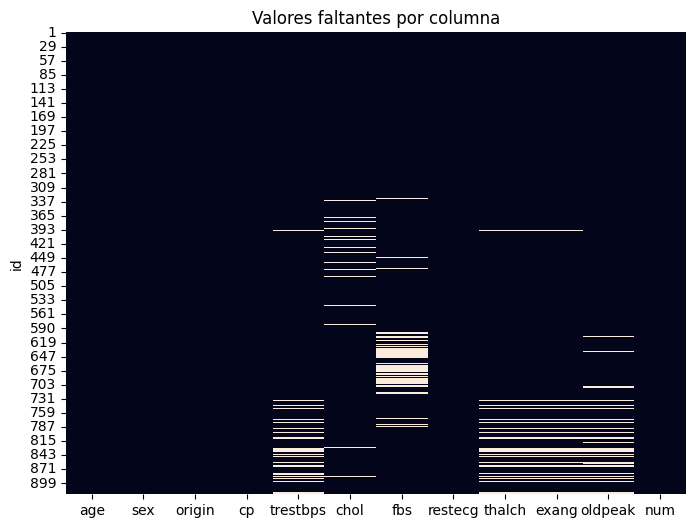

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(cardio_df.isna(), cbar=False)
plt.title('Valores faltantes por columna')
plt.show()

In [12]:
print(cardio_df[cardio_df['thalch'].isna()].isna().sum())

print(cardio_df[cardio_df['thalch'].isna()]['origin'].value_counts())

age          0
sex          0
origin       0
cp           0
trestbps    55
chol         3
fbs          0
restecg      0
thalch      55
exang       55
oldpeak     54
num          0
dtype: int64
origin
VA Long Beach    53
Hungary           1
Switzerland       1
Name: count, dtype: int64


**Variables con faltantes al mismo tiempo:** en el mapa de calor se ve un bloque de filas (más o menos del `id` 720 al 920) donde faltan juntas **`trestbps`**, **`thalch`**, **`exang`** y **`oldpeak`**. Lo comprobé con el código: de los 55 registros donde falta `thalch`, también falta `exang` en los 55, `trestbps` en 55 y `oldpeak` en 54. Además, 53 de esos 55 registros son de **VA Long Beach**.

**¿Tiene sentido desde el punto de vista médico?** Sí. `thalch` (frecuencia cardíaca máxima), `exang` (angina provocada por el ejercicio) y `oldpeak` (depresión del segmento ST por el ejercicio) se miden en la **misma prueba de esfuerzo**, donde el paciente hace ejercicio mientras le monitorean el corazón. Si a un paciente no se le hizo la prueba (por ejemplo, porque no podía hacer ejercicio o porque el hospital no la registró), es lógico que falten las tres juntas. `trestbps` es la presión en reposo, que normalmente se toma al inicio de esa misma prueba, así que también tiene sentido que falte junto con las demás.

En cambio, `chol` y `fbs` tienen faltantes en otras filas, porque salen de análisis de sangre y no de la prueba de esfuerzo. Por eso no las incluí en este grupo.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [13]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [14]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

Diagnóstico de faltantes de thalch respecto a age:


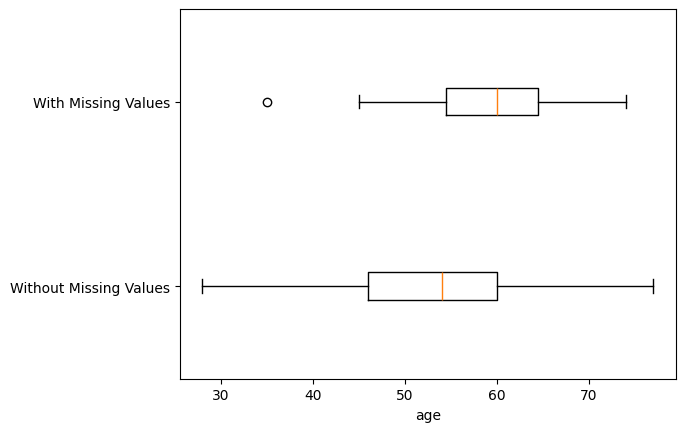

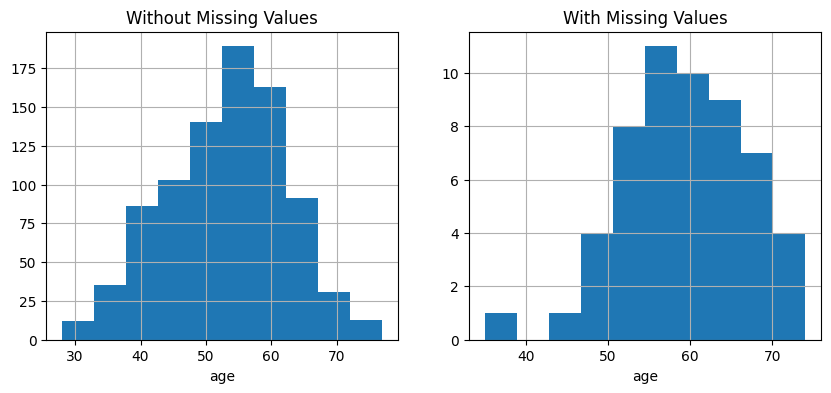

p-value of t-test: 1.5041244185890902e-06
Diagnóstico de faltantes de thalch respecto a chol:


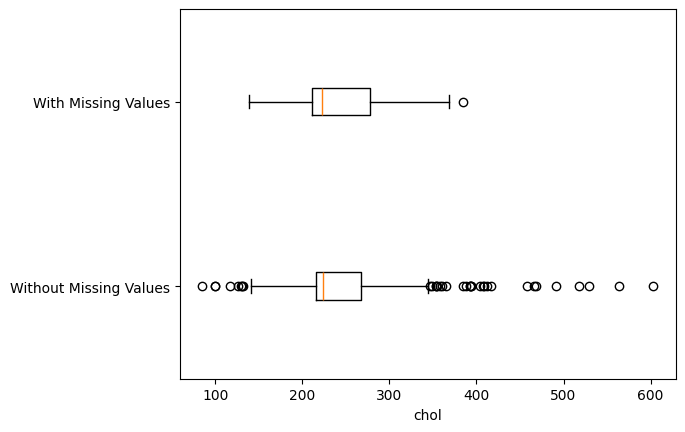

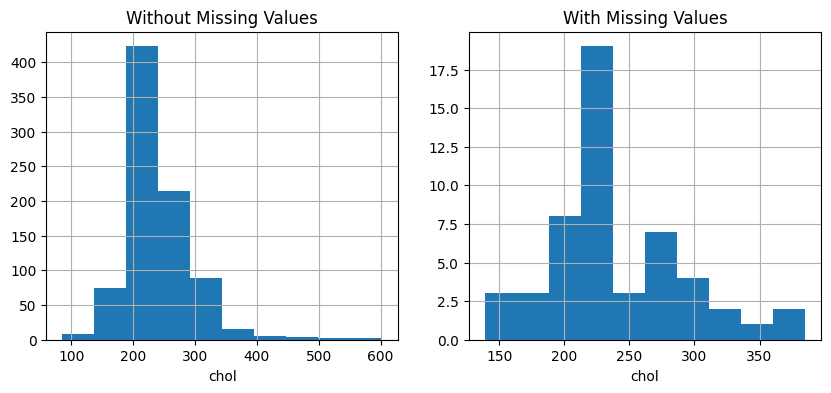

p-value of t-test: 0.7165289974295672
Diagnóstico de faltantes de thalch respecto a restecg:


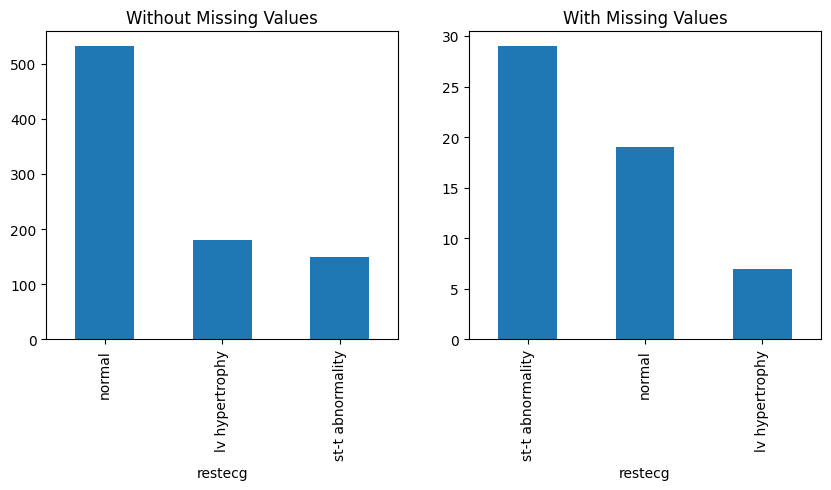

p-value of Chi_squared test: 1.1472889573985467e-09
Diagnóstico de faltantes de thalch respecto a cp:


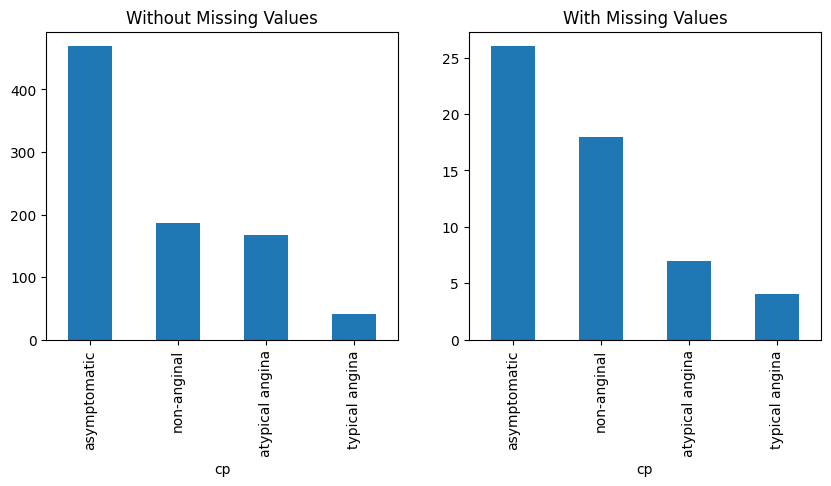

p-value of Chi_squared test: 0.15420097177251701


In [15]:
BM_MV = cardio_df['thalch'].isna()

for att in ['age', 'chol']:
    print('Diagnóstico de faltantes de thalch respecto a {}:'.format(att))
    Diagnose_MV_Numerical(cardio_df, att, BM_MV)

for att in ['restecg', 'cp']:
    print('Diagnóstico de faltantes de thalch respecto a {}:'.format(att))
    Diagnose_MV_Categorical(cardio_df, att, BM_MV)

In [16]:
for att in ['restecg', 'cp']:
    print(pd.crosstab(BM_MV, cardio_df[att], normalize='index').round(3), '\n')

restecg  lv hypertrophy  normal  st-t abnormality
thalch                                           
False             0.210   0.616             0.174
True              0.127   0.345             0.527 

cp      asymptomatic  atypical angina  non-anginal  typical angina
thalch                                                            
False          0.543            0.194        0.216           0.048
True           0.473            0.127        0.327           0.073 



**Conclusiones**

Separé los registros en dos grupos: los que tienen `thalch` vacío y los que no. Después comparé los dos grupos en 4 variables. Usé un nivel de significancia de 0.05, es decir, si el p-value es menor a 0.05, sí hay una diferencia importante entre los grupos.

| Variable | Prueba | p-value | ¿Hay diferencia? |
|---|---|---|---|
| `age` | t de Student | 1.50 × 10⁻⁶ | **Sí** |
| `chol` | t de Student | 0.717 | No |
| `restecg` | Chi-cuadrada | 1.15 × 10⁻⁹ | **Sí** |
| `cp` | Chi-cuadrada | 0.154 | No |

* **`age`**: en el boxplot se ve que los pacientes sin `thalch` son más grandes de edad (la mediana es de alrededor de 60 años, contra 54 de los demás). El p-value lo confirma.
* **`chol`**: los boxplots e histogramas de los dos grupos se parecen y el p-value es alto, así que no hay relación.
* **`restecg`**: aquí la diferencia es muy grande. En los registros sin `thalch`, el 52.7% tiene anomalía ST-T, mientras que en los demás solo el 17.4%. Y solo el 34.5% de los registros sin `thalch` tiene un electrocardiograma normal, contra el 61.6% de los demás.
* **`cp`**: las proporciones de los tipos de dolor son parecidas en los dos grupos y el p-value es mayor a 0.05, así que no hay diferencia.

**¿MCAR o MAR?** Los faltantes de `thalch` **no son MCAR**. Si fueran completamente al azar, los dos grupos deberían ser parecidos en todas las variables, pero en `age` y `restecg` son muy diferentes. Como los faltantes dependen de otras variables que sí tenemos registradas, el mecanismo es **MAR**.

Esto también concuerda con la pregunta 4: casi todos los faltantes son de VA Long Beach, y ahí hay más pacientes mayores y con anomalía ST-T. Además, tiene sentido que a pacientes mayores o con un electrocardiograma alterado no se les haya hecho la prueba de esfuerzo. Como `exang`, `oldpeak` y `trestbps` faltan en los mismos registros, esta conclusión también aplica para ellas. Por eso, en la siguiente pregunta, conviene imputarlas usando grupos de `restecg`.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [17]:
for col in ['trestbps', 'thalch', 'oldpeak']:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.median()))

cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(lambda x: x.where(x.notna(), x.mode()[0]))

cardio_df[['trestbps', 'thalch', 'oldpeak', 'exang']].isna().sum()

,0
trestbps,0
thalch,0
oldpeak,0
exang,0


Imputé por grupos de `restecg` las 4 variables que encontré en la pregunta 4:

* **`trestbps`**, **`thalch`** y **`oldpeak`** son numéricas, así que usé la **mediana** de cada grupo. Elegí la mediana porque no se ve afectada por los valores extremos, a diferencia de la media.
* **`exang`** es de verdadero/falso, así que no se le puede sacar la mediana. Por eso usé la **moda** (el valor más frecuente) de cada grupo.

Usé `restecg` para formar los grupos porque en la pregunta 5 vi que los faltantes sí están relacionados con esa variable.

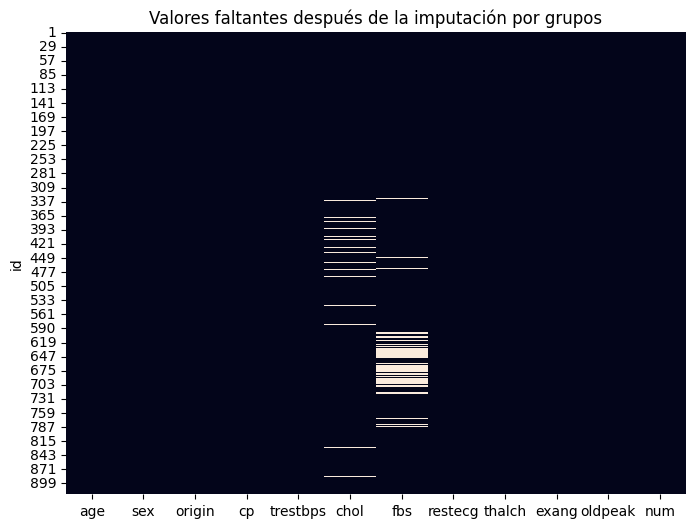

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(cardio_df.isna(), cbar=False)
plt.title('Valores faltantes después de la imputación por grupos')
plt.show()

En el nuevo mapa de calor ya no aparecen rayas en `trestbps`, `thalch`, `exang` ni `oldpeak`, así que la imputación funcionó. Solo quedan faltantes en `chol` y `fbs`, que voy a imputar en la siguiente pregunta.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [19]:
cardio_df.isna().sum()[cardio_df.isna().sum() > 0]

,0
chol,30
fbs,89


In [20]:
median_imputer = SimpleImputer(strategy='median')
cardio_df[['chol']] = median_imputer.fit_transform(cardio_df[['chol']])

mode_imputer = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = mode_imputer.fit_transform(cardio_df[['fbs']])

print('Mediana usada (chol):', median_imputer.statistics_)
print('Moda usada (fbs):', mode_imputer.statistics_)
print('Total de faltantes restantes:', cardio_df.isna().sum().sum())

Mediana usada (chol): [223.]
Moda usada (fbs): [False]
Total de faltantes restantes: 0


Después de la pregunta 6 solo quedaban faltantes en `chol` (30) y `fbs` (89). Los imputé con `SimpleImputer` usando toda la columna:

* **`chol` → `median`**: en la pregunta 3 vi que es la variable más sesgada (1.64) y con la curtosis más alta (6.57), o sea que tiene valores muy altos. Esos valores jalan la media hacia arriba (242.2), mientras que la mediana (223) representa mejor a un paciente típico. Por eso usé la mediana.
* **`fbs` → `most_frequent`**: es una variable de verdadero/falso, así que no se le puede sacar la media ni la mediana. Usé la moda, que es `False` (el 83% de los pacientes que sí tienen el dato).

No usé `mean` porque ninguna de las dos variables que faltaban es numérica con una distribución simétrica. Al final, el dataframe ya no tiene ningún valor faltante.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

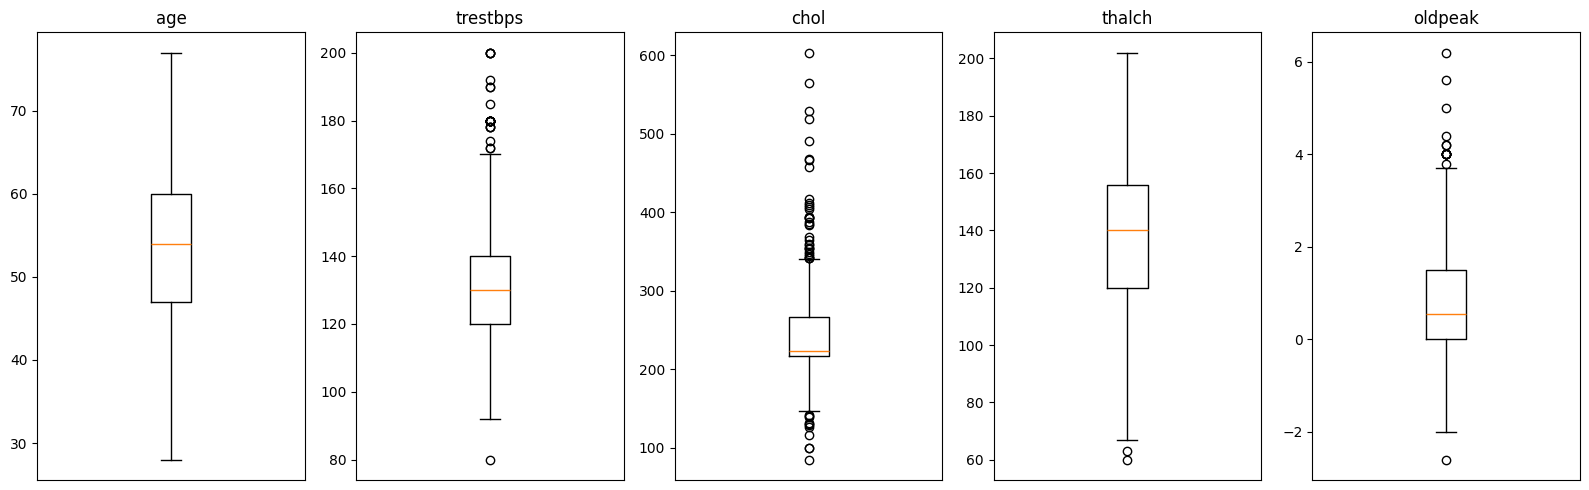

age: 0 atípicos -> []
trestbps: 27 atípicos -> [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
chol: 44 atípicos -> [ 85. 100. 100. 117. 126. 129. 131. 132. 139. 141. 142. 342. 342. 342.
 344. 347. 349. 353. 354. 355. 358. 360. 365. 369. 384. 385. 388. 392.
 393. 394. 394. 404. 407. 409. 412. 417. 458. 466. 468. 491. 518. 529.
 564. 603.]
thalch: 2 atípicos -> [60. 63.]
oldpeak: 16 atípicos -> [-2.6  3.8  4.   4.   4.   4.   4.   4.   4.   4.   4.2  4.2  4.4  5.
  5.6  6.2]


In [21]:
num_cols = cardio_df.select_dtypes(include='number').columns
fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 5))
outliers = {}
for ax, col in zip(axes, num_cols):
    bp = ax.boxplot(cardio_df[col])
    ax.set_title(col)
    ax.set_xticks([])
    outliers[col] = bp['fliers'][0].get_ydata()
plt.tight_layout()
plt.show()

for col, vals in outliers.items():
    print('{}: {} atípicos -> {}'.format(col, len(vals), np.sort(vals)))

Dibujé un boxplot por cada variable numérica y saqué los valores atípicos de `bp['fliers']`, que son los puntos que quedan fuera de los bigotes:

* **`age`**: no tiene atípicos.
* **`trestbps`**: 27 atípicos. Uno es bajo (80 mm Hg) y 26 son altos (entre 172 y 200 mm Hg).
* **`chol`**: es la que más atípicos tiene, 44. Hay 11 bajos (entre 85 y 142) y 33 altos (entre 342 y 603). Esto concuerda con lo que vi en la pregunta 3, donde salió con el sesgo y la curtosis más altos.
* **`thalch`**: 2 atípicos bajos (60 y 63).
* **`oldpeak`**: 16 atípicos. Uno es negativo (−2.6) y 15 son altos (entre 3.8 y 6.2).

Que un valor sea atípico no significa que esté mal. Por ejemplo, una presión de 200 o un colesterol de 603 sí pueden existir en pacientes con hipertensión o colesterol muy alto. Solo significa que están lejos de la mayoría de los datos.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [22]:
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print('Q1 = {}, Q3 = {}, IQR = {}'.format(Q1, Q3, IQR))
print('Límite inferior = {}, límite superior = {}'.format(lower, upper))

outliers_iqr = cardio_df[(cardio_df['trestbps'] < lower) | (cardio_df['trestbps'] > upper)]['trestbps']
print('Atípicos por IQR: {} -> {}'.format(len(outliers_iqr), np.sort(outliers_iqr.values)))

print('¿Coinciden con el boxplot?', np.array_equal(np.sort(outliers_iqr.values), np.sort(outliers['trestbps'])))

Q1 = 120.0, Q3 = 140.0, IQR = 20.0
Límite inferior = 90.0, límite superior = 170.0
Atípicos por IQR: 27 -> [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
¿Coinciden con el boxplot? True


Para `trestbps` calculé los cuartiles: **Q1 = 120** y **Q3 = 140**, así que el **IQR = 20**. Con eso, los límites quedan así:

* Límite inferior = 120 − 1.5 × 20 = **90**
* Límite superior = 140 + 1.5 × 20 = **170**

Todo valor menor a 90 o mayor a 170 es atípico. Salieron **27 atípicos**, exactamente los mismos que encontré con el boxplot en la pregunta 8 (el código lo confirma con `True`).

Coinciden porque el boxplot de matplotlib usa la misma regla: los bigotes llegan hasta 1.5 veces el IQR, y lo que queda fuera lo marca como atípico.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

In [23]:
print('Registros antes:', len(cardio_df))
cardio_df = cardio_df[(cardio_df['trestbps'] >= lower) & (cardio_df['trestbps'] <= upper)]
print('Registros después:', len(cardio_df))

Registros antes: 918
Registros después: 891


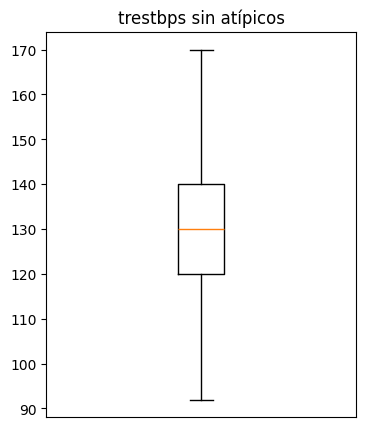

In [24]:
plt.figure(figsize=(4, 5))
plt.boxplot(cardio_df['trestbps'])
plt.xticks([])
plt.title('trestbps sin atípicos')
plt.show()

Eliminé los 27 registros que tenían `trestbps` fuera del rango de 90 a 170. El dataframe pasó de 918 a **891 registros**.

En el boxplot final ya no aparecen puntos atípicos: los datos van de 92 a 170 mm Hg y la caja sigue entre 120 y 140, así que al quitar los atípicos no aparecieron nuevos.

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude (Claude Opus 5.5)* [Modelo de lenguaje grande], utilizado para generación de código, depuración y apoyo en la redacción de las interpretaciones de resultados. https://claude.ai/

---